# Milestone 1: Affordable Housing and Parking Meters in NYC

## Team and individual contributions

| Member | Student ID | Research questions and charts | Data cleaning | Integration | Website part |
|---|---|---|---|---|---|
| Ahmed Sayed | 16008533 | Q1, Q2 | Housing dataset: missing values and duplicates | Aggregation of housing data | Dropdown filters |
| Mohannad Hany | 16008825 | Q3, Q4 | Transport dataset: missing values and duplicates | Aggregation of transport data | Search mode |
| Abdelrahman Mohamed | 16001205 | Q5, Q6 | Housing dataset: outliers (IQR + domain rules) | Merge and join-key justification | Generate Report callback |
| Mohamed Wael | 16003528 | Q7, Q8 | Transport dataset: outliers (domain rules) | Post-integration cleaning | Charts layout and styling |
| Kareem Alguineedy | 16007546 | Q9, Q10 | Standardizing dates, ZIPs and boroughs (both datasets) | EDA of the integrated data | Story section |
| Deema Seada | 16002455 | Q11, Q12 | Inconsistent categories and string cleaning | Feasibility check and notebook Markdown | Deployment, README, final testing |

## Datasets

- **Housing:** Affordable Housing Production by Building (HPD), dataset ID `hg8x-zxpr`  
  https://data.cityofnewyork.us/Housing-Development/Affordable-Housing-Production-by-Building/hg8x-zxpr
- **Transportation:** Parking Meters Locations & Status (DOT), dataset ID `693u-uax6`  
  https://data.cityofnewyork.us/Transportation/Parking-Meters-Locations-and-Status/693u-uax6

## Main research idea

Affordable housing production and parking-meter locations do not share a direct record-level key. The housing dataset includes building coordinates and community-board information, while the meter dataset includes meter coordinates but no matching housing project ID, ZIP code, community board, or project date. We therefore use geographic proximity: a grid-based neighborhood window is used to count active meters around each housing record and housing records around each meter. The resulting record-level measures are then summarized by borough, community board, and housing completion year.

The analysis is descriptive. It can identify spatial patterns and associations, but it cannot establish that parking meters cause housing development or that housing development causes changes in parking-meter availability.

## Research questions

1. How many active parking meters are there per 1,000 affordable housing units in each borough?
2. What share of affordable housing records are near an active meter, by building completion year?
3. How does nearby active-meter availability differ between new construction and preservation?
4. Is the share of three-bedroom-or-larger units associated with the number of nearby active meters?
5. How does the income-band composition of affordable housing relate to nearby active-meter counts?
6. Which community boards have more newly constructed affordable units, and how does nearby active-meter availability compare?
7. How do affordable housing locations and active parking-meter locations overlap geographically?
8. Are inactive meters more or less common near new affordable housing than elsewhere?
9. Are larger affordable housing records associated with more nearby active meters?
10. How do meter time-limit categories differ between meters near affordable housing and meters farther away?
11. Is the affordable-unit share of a building associated with nearby active-meter counts?
12. Does project duration differ between affordable housing records near an active meter and those without one?

## Prompts used

AI assistance (Claude) was used as a starting point for the plan, the code structure and the wording of some cells. The team ran the code on the real NYC Open Data files, checked the outputs and fixed the problems that appeared (for example the community board format, the meter coordinates and the size of the proximity window). The twelve figures are drawn with matplotlib so they render as images in any notebook viewer, including GitHub, which does not execute the scripts that an interactive Plotly output depends on.

| Step | Prompt (summary) | What we did with it |
|---|---|---|
| Project plan | Uploaded the Milestone 1 description and asked for the whole project step by step, with what to upload at each step | Used it as the order of work |
| Team table | Asked how to write the contribution table in the GitHub README | Filled it with our own split of the work |
| Research questions | Uploaded the two data dictionaries and asked for 12 research questions, two per member | Adjusted Q8 and Q9 after the EDA showed the meter data has only Active and Inactive status and very few off-street meters |
| Code style | Uploaded Labs 1, 2 and 6 and asked for the code to follow them | Kept the lab functions (isnull, IQR, boxplots, pd.merge) |
| Loading, EDA, cleaning | Asked for the code from scratch, step by step | Ran every step and checked the outputs |
| Fixes after the first run | Pasted our real outputs and asked for corrected code | Fixed the column names, the community board format, the meter coordinates and the proximity window |
| Comments and review | Asked for short comments and a review of the notebook against the Milestone 1 requirements | Added comments and the missing EDA plots |

## How to run

`pip install -r requirements.txt` from the repository root, then run this notebook top to bottom. It downloads both datasets from NYC Open Data, so an internet connection is required. The run rewrites the five CSV files in `Data/`.

## Scope and limitations

- The housing data represents records in the selected HPD dataset; a row should not automatically be interpreted as a unique newly built physical building without checking the dataset's record definitions.
- The parking-meter dataset is a location/status snapshot and may not represent historical meter availability when a housing project was completed.
- A parking meter is not the same thing as a parking space, and the analysis does not measure total parking supply.
- The grid method is an approximation of proximity, not an exact road-network walking distance.
- Missing or confidential housing coordinates cannot be assigned a reliable proximity count.
- Results describe associations, not causal effects.


# Step 1: Imports

In [1]:
# libraries we need
import os
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

# Step 2: Load the data

The notebook loads the two selected NYC Open Data datasets using their dataset IDs and the official CSV download endpoint. The saved execution output recorded 9,551 housing rows and 15,598 parking-meter rows at the time of that run. The notebook loads the full CSVs rather than a filtered sample, so no sampling filter is applied.

NYC Open Data is live, so the row counts can change slightly if the notebook is run again.

In [2]:
# the ids come from the dataset urls. both files are small enough to load in full
housing_id = 'hg8x-zxpr'
transport_id = '693u-uax6'
base_url = 'https://data.cityofnewyork.us/api/views/{}/rows.csv?accessType=download'

df_housing = pd.read_csv(base_url.format(housing_id), low_memory=False)
df_meters = pd.read_csv(base_url.format(transport_id), low_memory=False)

print(df_housing.shape, df_meters.shape)

(9551, 41) (15598, 17)


# Step 3: Simple column names

In [3]:
# lowercase + underscores for every column name, so we don't make typos later
def simple_names(df):
    df.columns = (df.columns.str.strip().str.lower().str.replace(r'[^a-z0-9]+', '_', regex=True).str.strip('_'))
    return df

df_housing = simple_names(df_housing)
df_meters = simple_names(df_meters)
print(df_housing.columns.tolist())
print(df_meters.columns.tolist())

['project_id', 'project_name', 'project_start_date', 'project_completion_date', 'building_id', 'number', 'street', 'borough', 'postcode', 'bbl', 'bin', 'community_board', 'council_district', 'census_tract', 'nta_neighborhood_tabulation_area', 'latitude', 'longitude', 'latitude_internal', 'longitude_internal', 'building_completion_date', 'reporting_construction_type', 'extended_affordability_only', 'prevailing_wage_status', 'extremely_low_income_units', 'very_low_income_units', 'low_income_units', 'moderate_income_units', 'middle_income_units', 'other_income_units', 'studio_units', '1_br_units', '2_br_units', '3_br_units', '4_br_units', '5_br_units', '6_br_units', 'unknown_br_units', 'counted_rental_units', 'counted_homeownership_units', 'all_counted_units', 'total_units']
['objectid', 'meter_number', 'status', 'pay_by_cell_number', 'meter_hours', 'parking_facility_name', 'facility', 'borough', 'on_street', 'side_of_street', 'from_street', 'to_street', 'latitude', 'longitude', 'x', 'y',

# Step 4: Dataset overview

The housing dataset contains 9,551 rows and 41 columns in the recorded run. It includes project/building identifiers, borough, postcode, community board, project and completion dates, building coordinates, construction type, income-band unit counts, bedroom unit counts, and total/countable units. Important data-quality issues visible in the EDA include missing dates, missing building identifiers and coordinates, and substantial missingness in individual income/bedroom unit fields.

The parking-meter dataset contains 15,598 rows and 17 columns in the recorded run. It includes meter identifiers, status, meter-hours text, facility type, borough, street information, latitude/longitude, projected X/Y coordinates, and a location field. The EDA shows a small number of missing statuses and meter-hour descriptions, inconsistent capitalization in status/facility categories, and many blank parking-facility names. A blank facility name is not automatically treated as an error because most records are on-street meters.

Both datasets contain geographic coordinates, which provide the bridge for the analysis. They do not share a direct project-to-meter key. The housing dataset also contains community-board and completion-date fields, while the meter dataset does not provide equivalent community-board or historical-date fields. For this reason, the record-level integration uses spatial proximity rather than a direct ID or time join.

A building can appear more than once: the data dictionary states that a building involved in several projects is repeated, and in this snapshot 123 buildings appear in 247 project records (122 in two records, one in three). Those records carry the same `total_units` for the building but different counted units per project, so `total_units` is never summed across records. `all_counted_units` is summed as recorded; counting each repeated building once instead would remove 1,154 units, or 0.36% of the citywide 320,946.

The datasets were selected because they represent the two required domains and contain usable geographic fields. The housing data has more than 9 columns (41), and the transportation data has more than 9 columns (17), satisfying the column-count requirement.

In [4]:
# first 5 rows of the housing data, just to see what it looks like
df_housing.head()

,project_id,project_name,project_start_date,project_completion_date,building_id,number,street,borough,postcode,bbl,...,2_br_units,3_br_units,4_br_units,5_br_units,6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units
0,68872,177-06 WEXFORD TERRACE,06/30/2026,NaN,991637.0,177-06,WEXFORD TERRACE,Queens,11432.0,4.098350e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,9.0,43
1,72436,ST. NICK'S. 819 GRAND STREET,06/30/2026,NaN,1021347.0,819,GRAND STREET,Brooklyn,11211.0,3.029220e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,187.0,NaN,187.0,187
2,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,21199.0,127,EDGECOMBE AVENUE,Manhattan,10030.0,1.020480e+09,...,20.0,NaN,NaN,NaN,NaN,NaN,25.0,NaN,25.0,25
3,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,28145.0,602,ST NICHOLAS AVENUE,Manhattan,10030.0,1.020480e+09,...,5.0,NaN,NaN,NaN,NaN,NaN,16.0,NaN,16.0,16
4,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,40555.0,129,WEST 133 STREET,Manhattan,10030.0,1.019180e+09,...,6.0,4.0,NaN,NaN,NaN,NaN,15.0,NaN,15.0,15


In [5]:
# same for the meters data
df_meters.head()

,objectid,meter_number,status,pay_by_cell_number,meter_hours,parking_facility_name,facility,borough,on_street,side_of_street,from_street,to_street,latitude,longitude,x,y,location
0,1006,1403126,Active,104013.0,2HR Com Mon-Sat 0700-1300 / 2HR Pas Mon-Sat 13...,NaN,On Street,Manhattan,10 AVENUE,W,WEST 57 STREET,WEST 58 STREET,40.769541,-73.988370,9.874713e+05,219641.421003,POINT (-73.9883702549362 40.7695407107263)
1,2581,4173035,Active,465693.0,2HR Pas Mon-Sat 0830-1900,NaN,On Street,Queens,QUEENS BOULEVARD,S,65 ROAD,66 AVENUE,40.728062,-73.857421,1.023768e+06,204561.513827,POINT (-73.8574209667672 40.728062477746)
2,3322,4443039,Active,418083.0,2HR Pas Mon-Sat 0900-1900,NaN,On Street,Queens,108 STREET,W,103 AVENUE,LIBERTY AVENUE,40.683971,-73.833657,1.030385e+06,188509.311679,POINT (-73.8336574468997 40.6839710124397)
3,3963,4151994,Active,412544.0,2HR Pas Mon-Sat 0900-1900,NaN,On Street,Queens,VAN DAM STREET,W,QUEENS BOULEVARD,47 AVENUE,40.743880,-73.933846,1.002581e+06,210299.065672,POINT (-73.933845988062 40.7438799157602)
4,4447,2373015,NaN,222234.0,NaN,NaN,NaN,Bronx,Webster Ave,E,East 167 St,East 168 St,40.831866,-73.909718,1.009234e+06,242361.204304,POINT (-73.9097183002857 40.8318655513281)


# Step 5: EDA of the housing data

The following cells inspect data types, descriptive statistics, missingness, duplicates, borough distribution, construction type, and the distribution of total units. In the recorded run, the dataset contained 9,551 rows and 41 columns, with 0 exact duplicate rows. The overall percentage of missing cells was approximately 33.11%, so missingness is concentrated in several optional identifiers, dates, coordinates, and unit-detail fields rather than being evenly distributed.

The recorded borough counts were Brooklyn 3,649; Bronx 2,630; Manhattan 1,485; Queens 1,342; and Staten Island 445. Construction type was nearly balanced: 4,785 Preservation records and 4,766 New Construction records. The recorded total-unit skewness was approximately 4.59, indicating a long right tail and motivating an outlier flag rather than automatically deleting large projects.

The plots below are saved outputs from a run against the snapshot described above; re-running the notebook top to bottom regenerates them from the current NYC Open Data files.


In [6]:
# column names, types and how many non-null values each one has
df_housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 41 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   project_id                        9551 non-null   int64  
 1   project_name                      9551 non-null   str    
 2   project_start_date                9551 non-null   str    
 3   project_completion_date           7732 non-null   str    
 4   building_id                       7602 non-null   float64
 5   number                            9551 non-null   str    
 6   street                            9551 non-null   str    
 7   borough                           9551 non-null   str    
 8   postcode                          7593 non-null   float64
 9   bbl                               7530 non-null   float64
 10  bin                               7530 non-null   float64
 11  community_board                   9551 non-null   str    
 12  council_district 

In [7]:
# basic statistics of the numeric columns
df_housing.describe()

,project_id,building_id,postcode,bbl,bin,council_district,census_tract,latitude,longitude,latitude_internal,...,2_br_units,3_br_units,4_br_units,5_br_units,6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units
count,9551.000000,7.602000e+03,7593.000000,7.530000e+03,7.530000e+03,9551.000000,7593.000000,7593.000000,7593.000000,7507.000000,...,6042.000000,3429.000000,561.000000,73.000000,27.000000,689.000000,6944.000000,2730.000000,9522.000000,9551.000000
mean,67125.247409,5.827297e+05,10780.411432,2.510122e+09,2.643422e+06,25.941891,11313.514553,40.747931,-73.919754,40.748301,...,17.500828,10.329542,5.074866,2.684932,3.592593,5.368650,37.445709,22.316117,33.705734,46.653544
std,8463.040347,4.010576e+05,504.437572,9.720933e+08,1.061980e+06,14.092078,25805.374184,0.083191,0.056561,0.083113,...,29.515159,17.156613,8.343823,3.431378,7.094197,34.147261,63.785594,68.288017,65.834105,92.482144
min,44218.000000,3.750000e+02,10001.000000,1.000050e+09,1.000000e+06,1.000000,1.000000,40.509910,-74.247685,40.510046,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,61418.500000,1.179762e+05,10453.000000,2.026850e+09,2.006548e+06,13.000000,215.000000,40.677031,-73.949682,40.677259,...,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,5.000000,1.000000,2.000000,3.000000
50%,68781.000000,8.056255e+05,11102.000000,3.008498e+09,3.005974e+06,27.000000,386.000000,40.731651,-73.923641,40.731724,...,7.000000,4.000000,2.000000,1.000000,1.000000,1.000000,13.000000,1.000000,8.000000,12.000000
75%,73850.500000,9.806888e+05,11221.000000,3.039568e+09,3.418164e+06,38.000000,2001.000000,40.826339,-73.890763,40.826523,...,18.000000,11.000000,6.000000,3.000000,3.000000,2.000000,41.000000,2.000000,30.000000,45.000000
max,82249.000000,1.022537e+06,11694.000000,5.080478e+09,5.174441e+06,51.000000,122704.000000,40.906630,-73.730624,40.906877,...,305.000000,193.000000,115.000000,23.000000,28.000000,536.000000,917.000000,489.000000,917.000000,1320.000000


In [8]:
# nulls per column, then the % of all cells that are null
null_values = df_housing.isnull().sum()
print(null_values[null_values > 0])

data_count = np.prod(df_housing.shape)
percent = (null_values.sum() / data_count) * 100
print(round(percent, 2), '% of all cells are null')

project_completion_date             1819
building_id                         1949
postcode                            1958
bbl                                 2021
bin                                 2021
census_tract                        1958
nta_neighborhood_tabulation_area    1958
latitude                            1958
longitude                           1958
latitude_internal                   2044
longitude_internal                  2044
building_completion_date            1666
extremely_low_income_units          7470
very_low_income_units               6151
low_income_units                    4046
moderate_income_units               7857
middle_income_units                 6860
other_income_units                  8191
studio_units                        6353
1_br_units                          3439
2_br_units                          3509
3_br_units                          6122
4_br_units                          8990
5_br_units                          9478
6_br_units      

In [9]:
# duplicates, and how many buildings we have per borough and per construction type
print('duplicates:', df_housing.duplicated().sum())
print(df_housing['borough'].value_counts(dropna=False))
print(df_housing['reporting_construction_type'].value_counts(dropna=False))

duplicates: 0
borough
Brooklyn         3649
Bronx            2630
Manhattan        1485
Queens           1342
Staten Island     445
Name: count, dtype: int64
reporting_construction_type
Preservation        4785
New Construction    4766
Name: count, dtype: int64


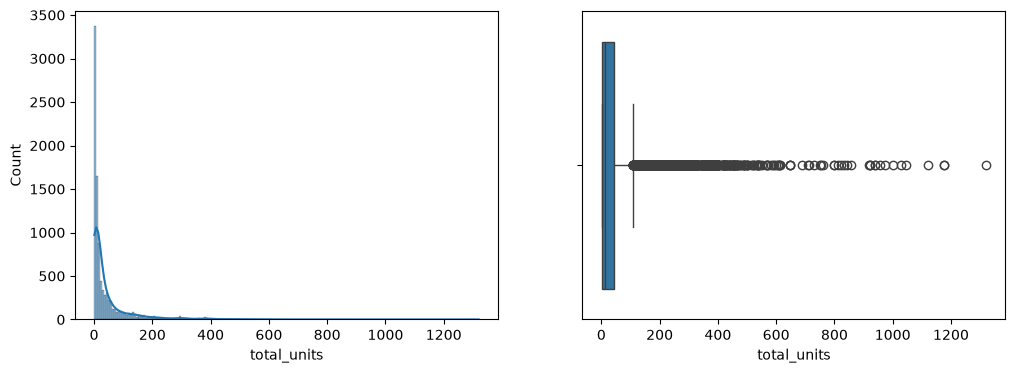

4.594373145026262


In [10]:
# how the building sizes are spread out. a skew far above 1 means a long tail of very big buildings
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
sns.histplot(df_housing['total_units'], kde=True, ax=ax[0])
sns.boxplot(x=df_housing['total_units'], ax=ax[1])
plt.show()
print(df_housing['total_units'].skew())

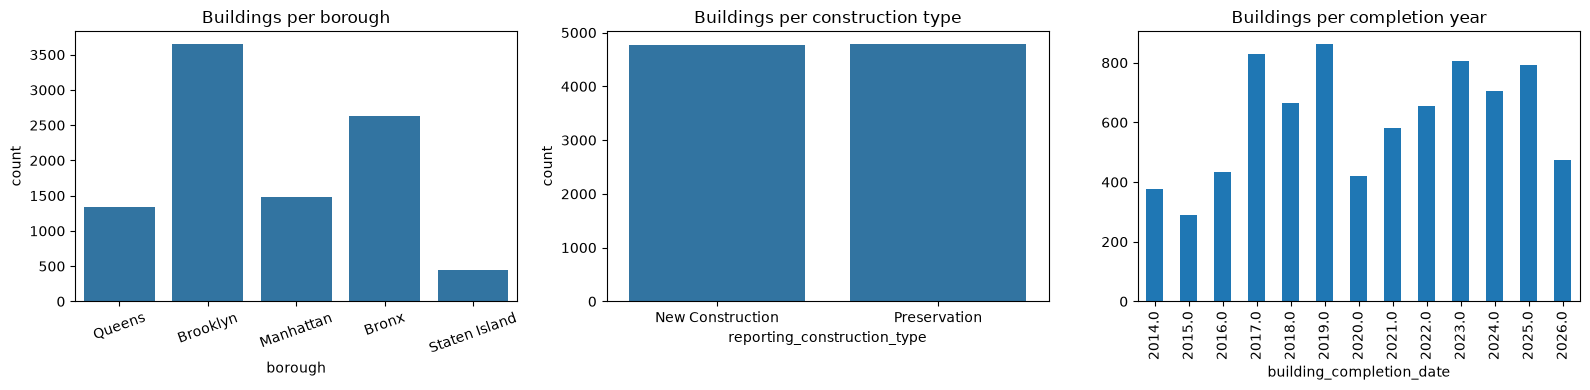

In [11]:
# initial plots for housing: buildings per borough, per construction type and per completion year
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
sns.countplot(x='borough', data=df_housing, ax=ax[0])
ax[0].set_title('Buildings per borough')
ax[0].tick_params(axis='x', rotation=20)
sns.countplot(x='reporting_construction_type', data=df_housing, ax=ax[1])
ax[1].set_title('Buildings per construction type')
years = pd.to_datetime(df_housing['building_completion_date'], errors='coerce').dt.year
years.value_counts().sort_index().plot(kind='bar', ax=ax[2])
ax[2].set_title('Buildings per completion year')
plt.tight_layout()
plt.show()

# Step 6: EDA of the meters data

These cells inspect meter data types, missing values, duplicates, borough distribution, status/facility categories, meter-hours text, and the projected X/Y fields. In the recorded run, the dataset contained 15,598 rows and 17 columns and had no exact duplicate rows. There were 37 missing status values, 49 missing meter-hours values, and 158 missing facility values. Status and facility values included capitalization variants, which are standardized during cleaning.

The recorded status counts included 12,796 `Active`, 2,763 `Inactive`, two lowercase `active`, and 37 missing values. The recorded facility values included 15,254 `On Street`, 184 `Off Street`, two `ON Street`, and 158 missing values. Parking-facility names are mostly blank because the dataset is dominated by on-street meters; this field is not required for the spatial analysis.

The notebook uses the provided latitude and longitude for spatial analysis. X and Y are projected coordinates and should not be interpreted as latitude and longitude.

The plots below are saved outputs from a run against the snapshot described above; re-running the notebook top to bottom regenerates them from the current NYC Open Data files.


In [12]:
# meters: column types and non-null counts
df_meters.info()

<class 'pandas.DataFrame'>
RangeIndex: 15598 entries, 0 to 15597
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   objectid               15598 non-null  int64  
 1   meter_number           15598 non-null  int64  
 2   status                 15561 non-null  str    
 3   pay_by_cell_number     15593 non-null  float64
 4   meter_hours            15549 non-null  str    
 5   parking_facility_name  174 non-null    str    
 6   facility               15440 non-null  str    
 7   borough                15598 non-null  str    
 8   on_street              15598 non-null  str    
 9   side_of_street         15594 non-null  str    
 10  from_street            15594 non-null  str    
 11  to_street              15598 non-null  str    
 12  latitude               15598 non-null  float64
 13  longitude              15598 non-null  float64
 14  x                      15598 non-null  float64
 15  y            

In [13]:
# meters: nulls, duplicates and the categories (look for typos like 'active' vs 'Active')
null_values = df_meters.isnull().sum()
print(null_values[null_values > 0])
print('duplicates:', df_meters.duplicated().sum())
print(df_meters['borough'].value_counts(dropna=False))
print(df_meters['status'].value_counts(dropna=False))
print(df_meters['facility'].value_counts(dropna=False))

status                      37
pay_by_cell_number           5
meter_hours                 49
parking_facility_name    15424
facility                   158
side_of_street               4
from_street                  4
dtype: int64
duplicates: 0
borough
Manhattan        5082
Brooklyn         4254
Queens           4242
Bronx            1681
Staten Island     339
Name: count, dtype: int64
status
Active      12796
Inactive     2763
NaN            37
active          2
Name: count, dtype: int64
facility
On Street     15254
Off Street      184
NaN             158
ON Street         2
Name: count, dtype: int64


In [14]:
# real values of meter_hours and the coordinates, look before cleaning
print(df_meters['meter_hours'].value_counts().head(20))
# x and y are in feet (not lat/lon), so later we use the latitude and longitude columns instead
df_meters[['x', 'y']].describe()

meter_hours
2HR Pas Mon-Sat 0900-1900                                                        4856
2HR Pas Mon-Sat 0800-1900                                                        2571
2HR Pas Mon-Sat 0830-1900                                                        2228
3HR Com Mon-Fri 0700-1800 / 6HR Pas Mon-Fri 1800-2400 / 6HR Pas Sat 0800-2400     369
3HR Com Mon-Sat 0700-1900                                                         214
2HR Pas Mon-Sat 0800-2200                                                         166
2HR Pas Mon-Sat 0930-1900                                                         162
3HR Com Mon-Fri 0800-1800                                                         158
2HR Pas 0800-1900 Mon-Thur / 4Hr Pas 0800-1900 Fri                                146
2HR Pas Mon-Sat 0830-2200                                                         135
3HR Com Mon-Fri 0700-1900                                                         133
3HR Com Mon-Fri 0800-1900                 

,x,y
count,1.559800e+04,15598.000000
mean,1.002742e+06,203946.497949
std,1.971854e+04,26929.727587
min,9.241857e+05,130074.111293
25%,9.884226e+05,186140.898437
50%,9.974637e+05,207911.917887
75%,1.015472e+06,217455.269782
max,1.067227e+06,270864.386798


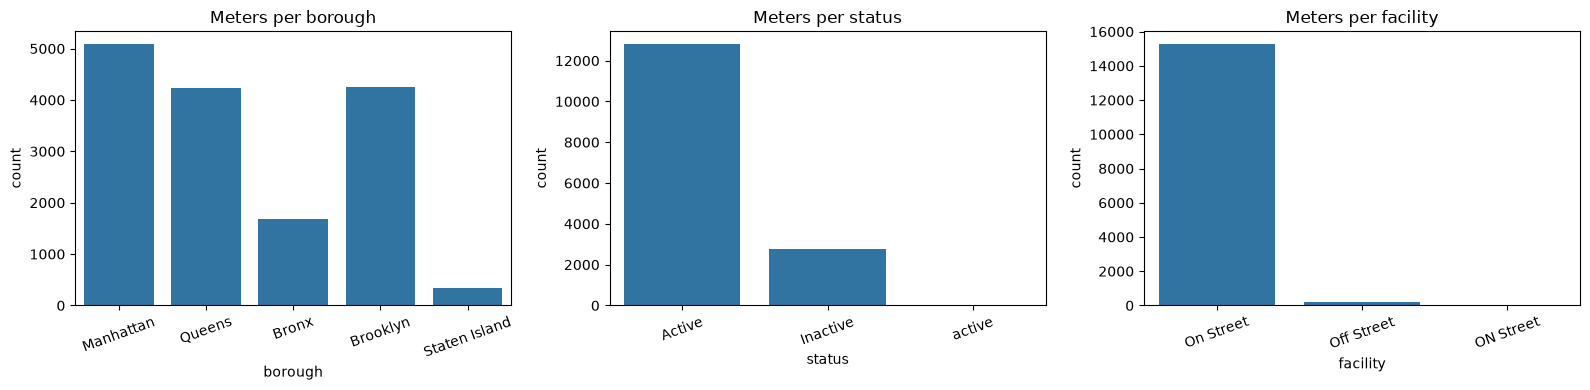

In [15]:
# initial plots for meters: meters per borough, status and facility (before cleaning, so the typos still show)
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
for col, a in zip(['borough', 'status', 'facility'], ax):
    sns.countplot(x=col, data=df_meters, ax=a)
    a.set_title('Meters per ' + col)
    a.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

# Step 7: Clean the housing data

Cleaning decisions implemented below:

- Standardize borough text to uppercase and remove surrounding whitespace so it matches the meter dataset.
- Remove exact duplicate rows. Do not remove records merely because a project may contain multiple building records.
- Parse project and building-completion dates; invalid dates become missing. Derive completion year and project duration, and set negative durations to missing.
- Treat negative unit counts as invalid. No negative count exists in this snapshot, so the rule is defensive only. The data dictionary does not say what a blank unit count means. We treat a blank as zero units (a building with no 4-bedroom units has nothing to report in that column) and test this assumption in the check cell after the cleaning, by comparing the income-band units with `all_counted_units`.
- Ensure `total_units` is not below `all_counted_units`, and remove rows where total units remain unavailable. Neither rule changes a row here: `total_units` is complete for all 9,551 records and is never below `all_counted_units`.
- Prefer internal lot-center coordinates, fall back to the dataset latitude/longitude, and set coordinates outside a broad NYC bounding box to missing.
- Flag confidential projects and unusually large records. Large records are retained because an IQR flag is not proof of an error.
- Create a community-board key that includes borough context, because board numbers can repeat across boroughs.
- Derive unit-composition shares only where the denominator is available.

The code preserves potentially valid large developments and records with missing coordinates rather than silently deleting them.

**Validation note:** the income-band consistency check that follows these diagnostics supports the assumption. In the recorded run the six income bands summed exactly to `all_counted_units` for 99.7% of all buildings — every one of the 9,522 rows that has a recorded total — and no row differed by more than one unit. The remaining 29 rows have no total to compare against.


In [16]:
# how is community_board written? it is text like BK-05, not a number
print(df_housing['community_board'].dtype)
print(df_housing['community_board'].value_counts(dropna=False).head(10))

str
community_board
BK-05    576
BK-03    552
MN-10    430
BX-12    430
BK-16    365
BK-17    354
BK-01    314
BK-04    298
BX-04    291
QN-12    286
Name: count, dtype: int64


In [17]:
# cleans the housing table: fixes text, dates, units and coordinates, and makes the columns we need for the questions
def clean_housing(df):
    df = df.copy()

    # same text format as the meters data
    df['borough'] = df['borough'].str.strip().str.upper()

    # exact duplicates only (a building can be in more than one project)
    df = df.drop_duplicates()

    # dates
    for col in ['project_start_date', 'building_completion_date']:
        df[col] = pd.to_datetime(df[col], errors='coerce')
    df['completion_year'] = df['building_completion_date'].dt.year
    df['duration_days'] = (df['building_completion_date'] - df['project_start_date']).dt.days
    df.loc[df['duration_days'] < 0, 'duration_days'] = np.nan
    # the dataset only covers projects after 2014
    df.loc[~df['completion_year'].between(2014, pd.Timestamp.today().year), 'completion_year'] = np.nan

    # unit columns: negative values are errors, blank means zero units
    unit_cols = [c for c in df.columns
                 if c.endswith('_units') and c not in ('all_counted_units', 'total_units')]
    df[unit_cols] = df[unit_cols].where(df[unit_cols] >= 0).fillna(0)

    # total units can not be smaller than the affordable units
    df['total_units'] = df['total_units'].fillna(df['all_counted_units'])
    df.loc[df['total_units'] < df['all_counted_units'], 'total_units'] = df['all_counted_units']
    df = df.dropna(subset=['total_units'])

    # coordinates: lot center first, then the address one, then check the NYC box
    df['lat'] = df['latitude_internal'].fillna(df['latitude'])
    df['lon'] = df['longitude_internal'].fillna(df['longitude'])
    outside = ~(df['lat'].between(40.4, 41.0) & df['lon'].between(-74.3, -73.6))
    df.loc[outside, ['lat', 'lon']] = np.nan

    # confidential projects have no address
    df['is_confidential'] = df['project_name'].str.contains('CONFIDENTIAL', case=False, na=False)

    # the data dictionary lists the community board as a number from 1 to 18, but
    # every row in this file already carries a borough-prefixed code such as BK-05,
    # so board numbers cannot collide across boroughs and the code is used as the key
    df['cb_id'] = df['community_board'].astype('string').str.strip().str.upper()

    # shares used in the research questions
    counted = df['all_counted_units'].replace(0, np.nan)
    big_cols = [c for c in ['3_br_units', '4_br_units', '5_br_units', '6_br_units'] if c in df.columns]
    df['share_3br_plus'] = df[big_cols].sum(axis=1) / counted
    income_cols = {
        'share_eli': 'extremely_low_income_units',
        'share_vli': 'very_low_income_units',
        'share_low': 'low_income_units',
        'share_moderate': 'moderate_income_units',
        'share_middle': 'middle_income_units',
        'share_other_income': 'other_income_units'
    }
    for share_col, units_col in income_cols.items():
        df[share_col] = df[units_col] / counted
    df['affordable_share'] = df['all_counted_units'] / df['total_units'].replace(0, np.nan)

    # outliers: IQR rule from Lab 2, we only flag very large buildings
    Q1 = df['total_units'].quantile(0.25)
    Q3 = df['total_units'].quantile(0.75)
    iqr = Q3 - Q1
    df['is_large_building'] = df['total_units'] > Q3 + 1.5 * iqr
    return df

df_housing_clean = clean_housing(df_housing)
print(df_housing.shape, '->', df_housing_clean.shape)

(9551, 41) -> (9551, 56)


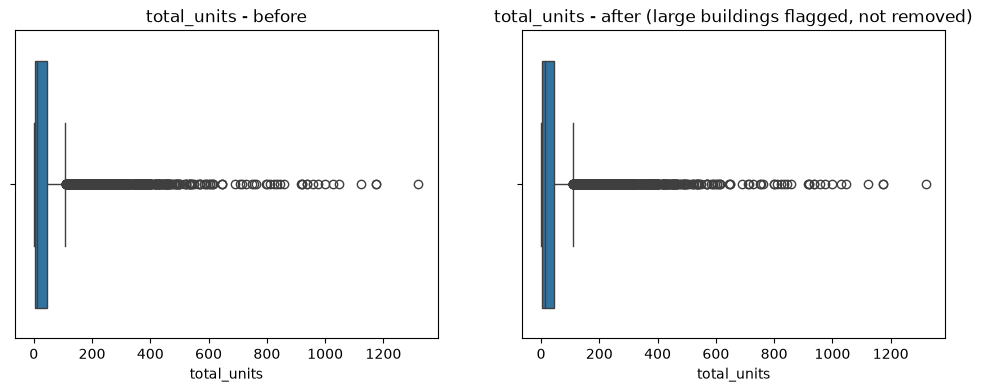

1171 large buildings flagged
1949 confidential rows
lat                1958
lon                1958
completion_year    1666
duration_days      1686
cb_id                 0
dtype: int64


In [18]:
# check the cleaning: boxplot before vs after, then counts of flagged, confidential and null values
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
sns.boxplot(x=df_housing['total_units'], ax=ax[0])
ax[0].set_title('total_units - before')
sns.boxplot(x=df_housing_clean['total_units'], ax=ax[1])
ax[1].set_title('total_units - after (large buildings flagged, not removed)')
plt.show()

print(df_housing_clean['is_large_building'].sum(), 'large buildings flagged')
print(df_housing_clean['is_confidential'].sum(), 'confidential rows')
print(df_housing_clean[['lat', 'lon', 'completion_year', 'duration_days', 'cb_id']].isnull().sum())

In [19]:
# check the "blank means zero" assumption: do the income-band units add up to the counted units?
income_cols = ['extremely_low_income_units', 'very_low_income_units', 'low_income_units',
               'moderate_income_units', 'middle_income_units', 'other_income_units']
income_sum = df_housing_clean[income_cols].sum(axis=1)
diff = (income_sum - df_housing_clean['all_counted_units']).abs()
print('income bands add up exactly to all_counted_units:', round((diff == 0).mean() * 100, 1), '% of buildings')
print('differ by more than 1 unit:', round((diff > 1).mean() * 100, 1), '% of buildings')

income bands add up exactly to all_counted_units: 99.7 % of buildings
differ by more than 1 unit: 0.0 % of buildings


# Step 8: Clean the meters data

Cleaning decisions implemented below:

- Standardize borough and status strings; missing status becomes `UNKNOWN` so it is not accidentally counted as active.
- Standardize facility labels and represent missing facility values as `Unknown`.
- Remove exact duplicate rows and then retain one row per `meter_number`.
- Convert the provided latitude/longitude to numeric values and flag coordinates outside the broad NYC bounding box as missing.
- Extract the first hour limit expressed as an `HR` rule from the `meter_hours` text. This is a simplified summary of potentially complex schedules; it does not fully represent multiple weekday/weekend rules in a single meter record.
- Keep longer limits (including 11–18 hours) because the EDA shows that these are actual source values, not necessarily data errors.
- Preserve records with unreadable or non-standard meter-hour descriptions; their parsed numeric time limit remains missing rather than being guessed. This affects meters with no text, meters with the text "Rate NOT Available", and meters whose limit is written in minutes (for example 30 minutes). They are left out of Q10 only.

In [20]:
# cleans the meters table: fixes text, removes repeated meters, checks the coordinates and reads the time limit
def clean_meters(df):
    df = df.copy()
    df['borough'] = df['borough'].str.strip().str.upper()
    df['status'] = df['status'].str.strip().str.upper().fillna('UNKNOWN')
    df['facility'] = df['facility'].str.strip().str.title().fillna('Unknown')

    # MeterNo is the dataset's unique identifier for a meter. Six rows in this
    # snapshot repeat a MeterNo with different text, so the first record per
    # meter is kept and the repeat is reported below.
    df = df.drop_duplicates()
    df = df.drop_duplicates(subset='meter_number')

    df['lat'] = pd.to_numeric(df['latitude'], errors='coerce')
    df['lon'] = pd.to_numeric(df['longitude'], errors='coerce')
    outside = ~(df['lat'].between(40.4, 41.0) & df['lon'].between(-74.3, -73.6))
    df.loc[outside, ['lat', 'lon']] = np.nan

    # first time limit in meter_hours (daytime rule), and "Com" means commercial
    hours = df['meter_hours'].astype('string')
    df['time_limit_hr'] = hours.str.extract(r'(\d+)\s*HR', flags=re.IGNORECASE)[0].astype(float)
    df['commercial_meter'] = hours.str.contains('Com', case=False, na=False)
    # groups for the time limit chart (Q10), the long all-day rules go in the last group
    df['time_limit_group'] = pd.cut(df['time_limit_hr'], bins=[0, 1, 2, 3, 6, 24],
                                    labels=['1 hr', '2 hr', '3 hr', '4-6 hr', '7+ hr (all day)'])
    return df

df_meters_clean = clean_meters(df_meters)
print(df_meters.shape, '->', df_meters_clean.shape)
print(df_meters_clean['status'].value_counts())
print(df_meters_clean['facility'].value_counts())
print(df_meters_clean['time_limit_hr'].value_counts(dropna=False))
print(len(df_meters) - len(df_meters_clean), 'rows removed as repeated meter numbers')

(15598, 17) -> (15592, 22)
status
ACTIVE      12793
INACTIVE     2763
UNKNOWN        36
Name: count, dtype: int64
facility
On Street     15254
Off Street      184
Unknown         154
Name: count, dtype: int64
time_limit_hr
2.0     12193
3.0      2414
1.0       403
6.0       151
4.0       135
NaN       106
15.0       89
12.0       73
5.0        16
18.0        7
11.0        3
16.0        2
Name: count, dtype: int64
6 rows removed as repeated meter numbers


In [21]:
# the 11 to 18 hour limits are real all-day rules, not mistakes, so we keep them
print(df_meters_clean[df_meters_clean['time_limit_hr'] >= 10]['meter_hours'].value_counts().head(10))

meter_hours
12HR Pas Mon-Sat 0700-1900     63
15HR Pas Mon-Sat 0800-2200     44
15HR Pas Mon-Sat 0700-2200     28
15HR Pas Mon-Sat 0600-2200      8
15 HR Pas Mon-Sat 0700-2200     8
18HR Pas Mon-Sat 0800-1900      7
12HR Pas Mon-Sat 0800-2000      5
12HR Pas Mon-Sat 0600-2200      5
11 HR Mon-Sat 0600-1800         3
16HR Pas Mon-Sat 0000-2200      2
Name: count, dtype: int64


In [22]:
# meters whose meter_hours has no number + "HR", so time_limit_hr stayed null
unread = df_meters_clean[df_meters_clean['time_limit_hr'].isna() & df_meters_clean['meter_hours'].notna()]
print(unread['meter_hours'].value_counts().head(10))

# size of each time limit group (used in Q10)
print(df_meters_clean['time_limit_group'].value_counts(dropna=False))

meter_hours
Rate NOT Available - Please request a NEW PERSO, and Once it is Ready, Please Create a New Report    33
30Min Com Mon-Sat 0600-2200                                                                          24
Mon-Fri 0700-1900 / Mon-Fri 1900-2200, Sat 0800-2200                                                  1
Name: count, dtype: int64
time_limit_group
2 hr               12193
3 hr                2414
1 hr                 403
4-6 hr               302
7+ hr (all day)      174
NaN                  106
Name: count, dtype: int64


# Step 9: Integration (the location link)

The datasets do not share a record-level identifier. The housing records have coordinates, and the parking-meter records have coordinates, so the integration uses spatial proximity.

Both datasets are assigned grid-cell indices using approximately 0.0009 degrees of latitude and 0.0012 degrees of longitude per cell (roughly 100 metres per side around NYC). For each target record, the code sums source records in a 7-by-7 cell window when `REACH = 3`. The window is square: its outer edges are roughly 300–400 metres from the target cell, while its corners can be farther away (roughly up to 500 metres). This is not a circular radius and is not a walking-distance calculation.

The building-side metric counts active meters in the surrounding window. The meter-side metric counts affordable-housing records and new-construction records in the surrounding window. Inactive meters are counted separately. Records without usable coordinates retain missing proximity values; they are not incorrectly assigned zero.

The sensitivity check compares smaller and larger windows. In the saved run, 63.9% of coordinate-valid buildings had an active meter within the 2-cell window, 75.7% within the 3-cell window, and 87.8% within the 5-cell window. This demonstrates that the proximity result depends on the selected window size.

Limitations: the grid is an approximation; meters are a snapshot rather than historical observations; multiple meter records may represent nearby meters on the same street; and confidential housing records without coordinates cannot be spatially linked.

In [23]:
# the location link: cut the map into small squares and count what falls in the squares around each point
# squares of about 100 m: 0.0009 degrees of latitude, 0.0012 degrees of longitude
CELL_LAT = 0.0009
CELL_LON = 0.0012
REACH = 3    # look 3 squares in every direction, so the window edge is 300 to 400 m away

def add_cells(df):
    df = df.copy()
    df['cell_lat'] = np.floor(df['lat'] / CELL_LAT)
    df['cell_lon'] = np.floor(df['lon'] / CELL_LON)
    return df


def neighbour_total(targets, sources, value_col=None):
    # for every row in targets: add up the sources that sit in the window of squares around it
    sources = sources.dropna(subset=['cell_lat', 'cell_lon'])
    if value_col is None:
        per_cell = sources.groupby(['cell_lat', 'cell_lon']).size().reset_index(name='n')
    else:
        per_cell = sources.groupby(['cell_lat', 'cell_lon'])[value_col].sum().reset_index(name='n')

    total = np.zeros(len(targets))
    for dlat in range(-REACH, REACH + 1):
        for dlon in range(-REACH, REACH + 1):
            # move the squares one step, so the merge matches each point with its neighbours
            shifted = per_cell.copy()
            shifted['cell_lat'] = shifted['cell_lat'] - dlat
            shifted['cell_lon'] = shifted['cell_lon'] - dlon
            merged = targets[['cell_lat', 'cell_lon']].merge(
                shifted, on=['cell_lat', 'cell_lon'], how='left')
            total += merged['n'].fillna(0).values

    result = pd.Series(total, index=targets.index)
    return result.where(targets['cell_lat'].notna())   # no coordinates -> unknown, not 0

In [24]:
# use the function in both directions: meters around each building, and buildings around each meter
buildings = add_cells(df_housing_clean)
meters = add_cells(df_meters_clean)

# helper columns so we can add up the time limits
meters['has_limit'] = meters['time_limit_hr'].notna().astype(int)
meters['limit_filled'] = meters['time_limit_hr'].fillna(0)

# only active meters count as parking, inactive ones are kept in a separate group
active = meters[meters['status'] == 'ACTIVE']
inactive = meters[meters['status'] == 'INACTIVE']
new_buildings = buildings[buildings['reporting_construction_type'].str.contains('new', case=False, na=False)]

# building side: what is around each affordable building
buildings['meters_nearby'] = neighbour_total(buildings, active)
buildings['inactive_nearby'] = neighbour_total(buildings, inactive)
limit_sum = neighbour_total(buildings, active, 'limit_filled')
limit_count = neighbour_total(buildings, active, 'has_limit')
buildings['avg_time_limit_nearby'] = limit_sum / limit_count.replace(0, np.nan)
buildings['near_meter'] = (buildings['meters_nearby'] > 0).astype(float).where(
    buildings['meters_nearby'].notna())

# meter side: how much affordable housing is around each meter
meters['buildings_nearby'] = neighbour_total(meters, buildings)
meters['new_buildings_nearby'] = neighbour_total(meters, new_buildings)
meters['near_housing'] = (meters['buildings_nearby'] > 0).astype(float).where(
    meters['buildings_nearby'].notna())
meters['near_new_housing'] = (meters['new_buildings_nearby'] > 0).astype(float).where(
    meters['new_buildings_nearby'].notna())

print(buildings['meters_nearby'].describe())
print('buildings near an active meter:', round(buildings['near_meter'].mean() * 100, 1), '%')
print('meters near affordable housing:', round(meters['near_housing'].mean() * 100, 1), '%')

count    7593.000000
mean       13.265376
std        16.597107
min         0.000000
25%         1.000000
50%         9.000000
75%        19.000000
max       151.000000
Name: meters_nearby, dtype: float64
buildings near an active meter: 75.7 %
meters near affordable housing: 77.2 %


In [25]:
# does the result depend on the window size? try 2, 3 and 5 squares
for reach in [2, 3, 5]:
    REACH = reach
    test = neighbour_total(buildings, active)
    print(reach, 'squares ->', round((test.dropna() > 0).mean() * 100, 1), '% of buildings near a meter')
REACH = 3   # back to the value we use

2 squares -> 63.9 % of buildings near a meter


3 squares -> 75.7 % of buildings near a meter


5 squares -> 87.8 % of buildings near a meter


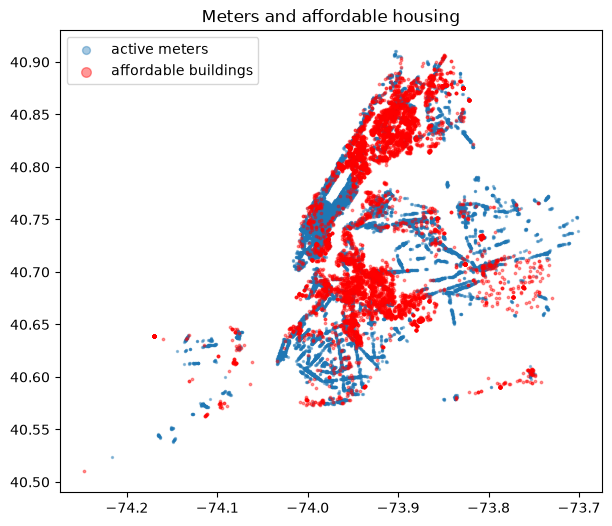

In [26]:
# quick map to check both datasets are in the right place (blue = meters, red = buildings)
# validation plot: both datasets on one map
plt.figure(figsize=(7, 6))
plt.scatter(active['lon'], active['lat'], s=2, alpha=0.4, label='active meters')
plt.scatter(buildings['lon'], buildings['lat'], s=3, alpha=0.4, color='red', label='affordable buildings')
plt.legend(markerscale=4)
plt.title('Meters and affordable housing')
plt.show()

# Step 10: Aggregation

The notebook creates summaries at three levels, each tied to a research question:

- **Borough:** combines active-meter counts with affordable-unit totals to calculate active meters per 1,000 affordable units (Q1). The ratio divides all active meters in a borough by that borough's affordable units, so it describes the borough as a whole and not only the meters near the housing. An outer join preserves boroughs present in either summary; the saved EDA showed that the borough labels match.
- **Community board:** compares newly constructed affordable units with average nearby active-meter counts (Q6). The community-board key includes borough context to avoid combining identically numbered boards from different boroughs.
- **Completion year:** summarizes affordable housing records and the share near an active meter (Q2). Records without a usable completion year are excluded from this year-level summary and remain in the record-level dataset.

`affordable_units` sums `all_counted_units` over housing records. Because 123 buildings appear in more than one project record, this counts units per project record rather than per physical building. The effect is small: the 247 records of repeated buildings carry 21,098 counted units, 6.6% of the citywide 320,946, but most of that belongs to each building's first record, so counting every building once instead removes only 1,154 units (0.36%). The difference is disclosed in the limitations.

Aggregation avoids attempting to match individual housing and meter records as if they described the same entity. The spatial proximity measures are computed first, then summarized at interpretable geographic or temporal levels.

In [27]:
# summary tables: by borough (Q1), by community board (Q6) and by completion year (Q2)
housing_by_borough = buildings.groupby('borough').agg(
    buildings=('borough', 'size'),
    affordable_units=('all_counted_units', 'sum'),
    share_near_meter=('near_meter', 'mean'),
    avg_meters_nearby=('meters_nearby', 'mean')).reset_index()

meters_by_borough = meters.groupby('borough').agg(
    meters_all=('borough', 'size'),
    meters_active=('status', lambda s: (s == 'ACTIVE').sum()),
    meters_inactive=('status', lambda s: (s == 'INACTIVE').sum())).reset_index()

# borough names must match in both, otherwise the merge creates fake rows
print(set(housing_by_borough['borough']) ^ set(meters_by_borough['borough']))

borough_summary = pd.merge(housing_by_borough, meters_by_borough, on='borough', how='outer')

# Q6 is specifically about new construction, so do not mix preservation records into this table.
new_buildings = buildings[
    buildings['reporting_construction_type'].str.contains('new', case=False, na=False)
].copy()

cb_summary = (new_buildings.dropna(subset=['cb_id']).groupby('cb_id')
              .agg(borough=('borough', 'first'),
                   new_buildings=('borough', 'size'),
                   new_affordable_units=('all_counted_units', 'sum'),
                   avg_meters_nearby=('meters_nearby', 'mean'),
                   share_near_meter=('near_meter', 'mean'))
              .reset_index())

year_summary = (buildings.dropna(subset=['completion_year']).groupby('completion_year')
                .agg(buildings=('borough', 'size'),
                     affordable_units=('all_counted_units', 'sum'),
                     share_near_meter=('near_meter', 'mean'))
                .reset_index())
year_summary['completion_year'] = year_summary['completion_year'].astype(int)

print(borough_summary)
print(cb_summary.shape, year_summary.shape)

set()
         borough  buildings  affordable_units  share_near_meter  \
0          BRONX       2630          106661.0          0.812700   
1       BROOKLYN       3649           90784.0          0.656321   
2      MANHATTAN       1485           74338.0          0.971408   
3         QUEENS       1342           42952.0          0.713921   
4  STATEN ISLAND        445            6211.0          0.155039   

   avg_meters_nearby  meters_all  meters_active  meters_inactive  
0          10.344906        1680           1413              263  
1           9.571937        4254           3672              580  
2          25.861330        5078           3960             1105  
3          15.329502        4241           3470              757  
4           2.248062         339            278               58  
(59, 6) (13, 4)


# Step 11: Post-integration cleaning (required)

After the borough-level outer join, missing meter or housing counts are filled with zero only for the count columns, because absence from one side of the summary means no matching borough summary row. Proximity measures for individual records without coordinates remain missing, not zero.

The final tables remove redundant source-coordinate and helper columns that are not needed by the website. Date, year, identifier, and postcode fields are converted to consistent types. Final duplicate checks are applied before export. The cells below report remaining missing values and final shapes so the cleaning can be validated after rerunning.

In [28]:
# after the join: boroughs with no meters row get 0, then meters per 1000 affordable units for Q1
# 1) new missing values from the join
count_cols = ['meters_all', 'meters_active', 'meters_inactive', 'buildings', 'affordable_units']
borough_summary[count_cols] = borough_summary[count_cols].fillna(0)
borough_summary['meters_per_1000_units'] = (
    borough_summary['meters_active'] / (borough_summary['affordable_units'] / 1000))
borough_summary = borough_summary.replace([np.inf, -np.inf], np.nan)
print(borough_summary.isnull().sum())

borough                  0
buildings                0
affordable_units         0
share_near_meter         0
avg_meters_nearby        0
meters_all               0
meters_active            0
meters_inactive          0
meters_per_1000_units    0
dtype: int64


In [29]:
# drop the columns we don't need and fix the data types
# 2) redundant columns
# Keep the cleaned lat/lon fields for the website map; remove only the raw source coordinates.
drop_cols = ['latitude', 'longitude', 'latitude_internal', 'longitude_internal',
             'number', 'street', 'bbl', 'bin', 'council_district', 'cell_lat', 'cell_lon']
buildings_final = buildings.drop(columns=[c for c in drop_cols if c in buildings.columns])
# Keep cleaned lat/lon for mapping; remove raw/projected coordinate fields and helper columns.
meters_final = meters.drop(columns=[c for c in ['latitude', 'longitude', 'x', 'y', 'location',
                                                 'cell_lat', 'cell_lon', 'limit_filled', 'has_limit']
                                    if c in meters.columns])

# 3) data types
buildings_final['completion_year'] = buildings_final['completion_year'].astype('Int64')
# these two were read as text / decimals
buildings_final['project_completion_date'] = pd.to_datetime(buildings_final['project_completion_date'], errors='coerce')
buildings_final['building_id'] = pd.to_numeric(buildings_final['building_id'], errors='coerce').astype('Int64')
buildings_final['postcode'] = (pd.to_numeric(buildings_final['postcode'], errors='coerce')
                               .astype('Int64').astype('string').str.zfill(5))
buildings_final = buildings_final.drop_duplicates()
meters_final = meters_final.drop_duplicates()

print(buildings_final.shape, meters_final.shape)
print(buildings_final.dtypes)
print(buildings_final[['meters_nearby', 'completion_year', 'cb_id']].isnull().sum())

(9551, 51) (15592, 21)
project_id                                   int64
project_name                                   str
project_start_date                  datetime64[us]
project_completion_date             datetime64[us]
building_id                                  Int64
borough                                        str
postcode                                    string
community_board                                str
census_tract                               float64
nta_neighborhood_tabulation_area               str
building_completion_date            datetime64[us]
reporting_construction_type                    str
extended_affordability_only                    str
prevailing_wage_status                         str
extremely_low_income_units                 float64
very_low_income_units                      float64
low_income_units                           float64
moderate_income_units                      float64
middle_income_units                        float64
other_in

# Step 12: Save the integrated data

The notebook exports the record-level integrated housing and meter tables and the borough, community-board, and completion-year summaries as CSV files in the `Data/` directory.

**Website handoff note:** the exported integrated tables retain the cleaned `lat` and `lon` fields so the website can build a geographic visualization. The website that reads these files lives in `website/` in the same repository, is deployed at <https://abdelrahmanahmed-16001205.github.io/Data-eng-proj/>, and is documented in the README.


In [30]:
# save the final tables, the website will load these files
os.makedirs('Data', exist_ok=True)
buildings_final.to_csv('Data/buildings_integrated.csv', index=False)
meters_final.to_csv('Data/meters_integrated.csv', index=False)
borough_summary.to_csv('Data/borough_summary.csv', index=False)
cb_summary.to_csv('Data/community_board_summary.csv', index=False)
year_summary.to_csv('Data/year_summary.csv', index=False)
print(os.listdir('Data'))

['borough_summary.csv', 'buildings_integrated.csv', 'community_board_summary.csv', 'meters_integrated.csv', 'year_summary.csv']


# Step 13: Research questions and visualizations

Each of the twelve research questions is answered by one figure. The figures are drawn with matplotlib, so they are saved as PNG images and render in every notebook viewer, including GitHub's, which does not execute the scripts an interactive Plotly output needs. The dashboard in `website/` draws the same twelve questions as interactive SVG charts.

Most of the twelve questions compare a housing attribute with the same proximity measure. A scatter of several thousand points is not evidence on its own, so the next cell prints one association measure per question: Spearman's rank correlation for the continuous pairs, Mann-Whitney U for the two-group comparisons, and a chi-square test for the two contingency tables (Q8 and Q10). Spearman is used because the proximity counts are heavily skewed and the shares are bounded. The p-values are descriptive: with n above 7,000 a correlation of 0.05 is already "significant", so the size of rho matters far more than the p-value.

**Notes on reading the charts:**

- Q4, Q5 and Q11 use shares of `all_counted_units`, so records where that number is missing have no share and are not plotted.
- In Q5, `other_income_units` are units reserved for building superintendents (data dictionary), so that panel is not an income band in the same sense as the other five.
- Q1 is a borough-wide ratio: all active meters in the borough over all affordable units in the borough, not only the meters near housing.
- Q7 shows locations only. Many points overlap in dense areas, so the map shows where both exist but not how many.
- Q12 measures the days from the project start date, which the data dictionary defines as the loan closing or regulatory agreement, to the building completion date. It is not construction time.


In [31]:
# Association statistics behind Q2 to Q12.
# Spearman's rho for the continuous pairs, Mann-Whitney U for the two group
# comparisons, and a chi-square test for the two contingency tables.
import matplotlib.ticker as mticker
from scipy import stats

BOROUGH_COLORS = {
    'BRONX': '#b3261e',
    'BROOKLYN': '#0a6b3d',
    'MANHATTAN': '#1f4e79',
    'QUEENS': '#8a5a00',
    'STATEN ISLAND': '#4a5f66',
}

income_share_cols = ['share_eli', 'share_vli', 'share_low',
                     'share_moderate', 'share_middle', 'share_other_income']


def spearman(label, x, y):
    pair = pd.DataFrame({'x': x, 'y': y}).dropna()
    rho, p = stats.spearmanr(pair['x'], pair['y'])
    return {'question': label, 'test': 'Spearman rho', 'n': len(pair),
            'statistic': round(float(rho), 3), 'p_value': f'{p:.2g}'}


def mannwhitney(label, first, second):
    first, second = first.dropna(), second.dropna()
    u, p = stats.mannwhitneyu(first, second, alternative='two-sided')
    return {'question': label, 'test': 'Mann-Whitney U', 'n': len(first) + len(second),
            'statistic': int(u), 'p_value': f'{p:.2g}'}


def chi_square(label, table):
    chi2, p, dof, expected = stats.chi2_contingency(table)
    return {'question': label, 'test': f'chi-square (df={dof})',
            'n': int(table.values.sum()), 'statistic': round(float(chi2), 1),
            'p_value': f'{p:.2g}'}


near = buildings.dropna(subset=['meters_nearby'])
rows = [
    spearman('Q2 completion year vs share near a meter',
             year_summary['completion_year'], year_summary['share_near_meter']),
    mannwhitney('Q3 new construction vs preservation',
                near.loc[near['reporting_construction_type'] == 'New Construction', 'meters_nearby'],
                near.loc[near['reporting_construction_type'] == 'Preservation', 'meters_nearby']),
    spearman('Q4 3BR+ share vs nearby meters',
             buildings['share_3br_plus'], buildings['meters_nearby']),
]
for band in income_share_cols:
    rows.append(spearman(f'Q5 {band} vs nearby meters', buildings[band], buildings['meters_nearby']))
rows += [
    spearman('Q6 new units vs average meters, community board',
             cb_summary['new_affordable_units'], cb_summary['avg_meters_nearby']),
    spearman('Q9 total units vs nearby meters',
             buildings['total_units'], buildings['meters_nearby']),
    spearman('Q11 affordable share vs nearby meters',
             buildings['affordable_share'], buildings['meters_nearby']),
]

# Q8: status against proximity to new housing. The UNKNOWN group holds only 36 of
# 15,592 meters, which would leave expected counts far below 5, so the test uses
# the ACTIVE and INACTIVE rows only. The Q8 chart still shows all three groups.
q8_test = meters.dropna(subset=['near_new_housing', 'status'])
q8_test = q8_test[q8_test['status'].isin(['ACTIVE', 'INACTIVE'])]
rows.append(chi_square('Q8 status vs new-housing proximity',
                       pd.crosstab(q8_test['near_new_housing'], q8_test['status'])))

# Q10: time-limit group against proximity to affordable housing.
q10_test = meters.dropna(subset=['time_limit_group', 'near_housing'])
rows.append(chi_square('Q10 time limit vs housing proximity',
                       pd.crosstab(q10_test['near_housing'], q10_test['time_limit_group'])))

q12 = buildings.dropna(subset=['duration_days', 'near_meter'])
rows.append(mannwhitney('Q12 duration, meter vs no meter',
                        q12.loc[q12['near_meter'] == 1, 'duration_days'],
                        q12.loc[q12['near_meter'] == 0, 'duration_days']))

# sort by question number so the table reads Q2, Q3, Q4 ... Q12
association_results = pd.DataFrame(rows)
association_results['order'] = association_results['question'].str.extract(r'^Q(\d+)').astype(int)
association_results = (association_results.sort_values('order')
                       .drop(columns='order')
                       .reset_index(drop=True))
print(association_results.to_string(index=False))


                                       question              test     n   statistic p_value
       Q2 completion year vs share near a meter      Spearman rho    13       0.456    0.12
            Q3 new construction vs preservation    Mann-Whitney U  7593 7622439.000 2.6e-06
                 Q4 3BR+ share vs nearby meters      Spearman rho  7564      -0.178 5.6e-55
                  Q5 share_eli vs nearby meters      Spearman rho  7564       0.009    0.43
                  Q5 share_vli vs nearby meters      Spearman rho  7564      -0.050 1.2e-05
                  Q5 share_low vs nearby meters      Spearman rho  7564      -0.040 0.00047
             Q5 share_moderate vs nearby meters      Spearman rho  7564       0.029   0.011
               Q5 share_middle vs nearby meters      Spearman rho  7564       0.156 1.4e-42
         Q5 share_other_income vs nearby meters      Spearman rho  7564       0.034  0.0028
Q6 new units vs average meters, community board      Spearman rho    59      -0.

## Q1. Active parking meters per 1,000 affordable housing units

Ahmed Sayed. A borough-wide ratio: active meters in the borough divided by the borough's affordable units. It describes the borough as a whole, not only the meters near housing.


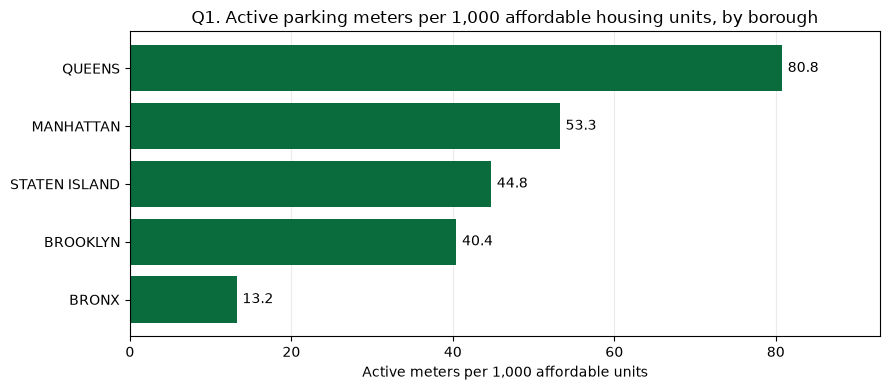

In [32]:
q1 = borough_summary.dropna(subset=['meters_per_1000_units']).sort_values('meters_per_1000_units')

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(q1['borough'], q1['meters_per_1000_units'], color='#0a6b3d')
ax.bar_label(bars, fmt='%.1f', padding=4)
ax.set_xlabel('Active meters per 1,000 affordable units')
ax.set_title('Q1. Active parking meters per 1,000 affordable housing units, by borough')
ax.set_xlim(0, q1['meters_per_1000_units'].max() * 1.15)
ax.grid(axis='x', alpha=.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## Q2. Share of housing records near an active meter, by completion year

Ahmed Sayed. Each point compares buildings completed in that year with the meters that exist today, so the series mixes a historical completion date with a current meter snapshot.


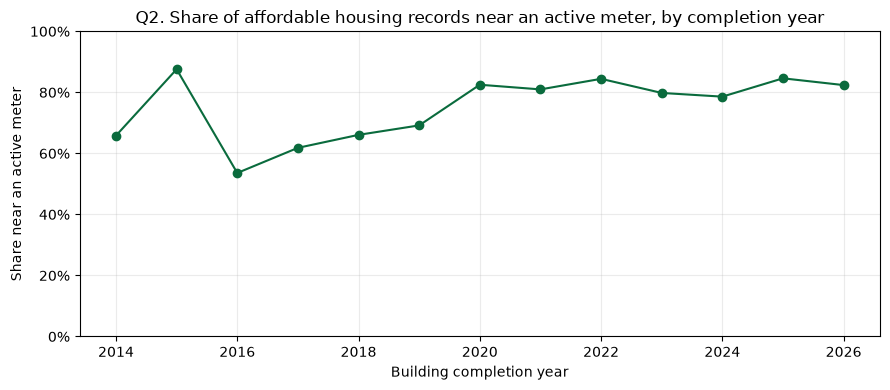

In [33]:
q2 = year_summary.dropna(subset=['completion_year', 'share_near_meter']).sort_values('completion_year')

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(q2['completion_year'], q2['share_near_meter'], marker='o', color='#0a6b3d')
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel('Building completion year')
ax.set_ylabel('Share near an active meter')
ax.set_title('Q2. Share of affordable housing records near an active meter, by completion year')
ax.grid(alpha=.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## Q3. Nearby active meters: new construction vs. preservation

Mohannad Hany. Boxes show the median and quartiles; outliers are hidden because the distribution has a long right tail.


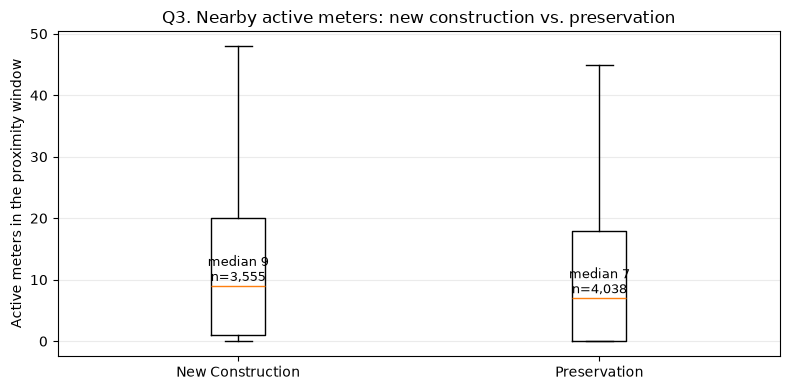

In [34]:
q3 = buildings.dropna(subset=['meters_nearby'])
new_units = q3.loc[q3['reporting_construction_type'] == 'New Construction', 'meters_nearby']
preserved = q3.loc[q3['reporting_construction_type'] == 'Preservation', 'meters_nearby']

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([new_units, preserved], tick_labels=['New Construction', 'Preservation'], showfliers=False)
for position, series in enumerate([new_units, preserved], start=1):
    ax.text(position, series.median() + 0.8, f'median {series.median():.0f}\nn={len(series):,}',
            ha='center', fontsize=9)
ax.set_ylabel('Active meters in the proximity window')
ax.set_title('Q3. Nearby active meters: new construction vs. preservation')
ax.grid(axis='y', alpha=.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## Q4. Three-bedroom-plus unit share vs. nearby active meters

Mohannad Hany. The black line is the median number of nearby meters within each decile of the bedroom share, so the trend is readable despite the point cloud.


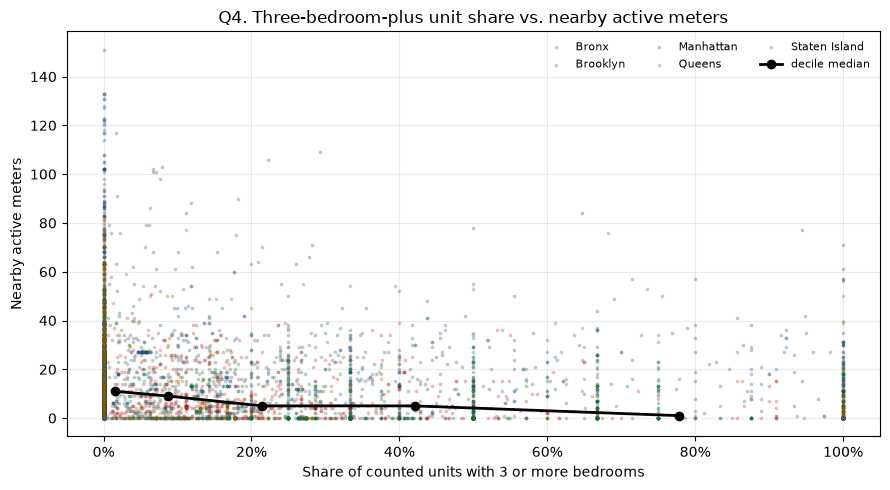

In [35]:
q4 = buildings.dropna(subset=['share_3br_plus', 'meters_nearby'])

fig, ax = plt.subplots(figsize=(9, 5))
for borough, colour in BOROUGH_COLORS.items():
    part = q4[q4['borough'] == borough]
    ax.scatter(part['share_3br_plus'], part['meters_nearby'], s=7, alpha=.3,
               color=colour, linewidths=0, label=borough.title())
deciles = pd.qcut(q4['share_3br_plus'], 10, duplicates='drop')
medians = q4.groupby(deciles, observed=True)['meters_nearby'].median()
ax.plot([interval.mid for interval in medians.index], medians.values,
        color='black', marker='o', linewidth=2, label='decile median')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel('Share of counted units with 3 or more bedrooms')
ax.set_ylabel('Nearby active meters')
ax.set_title('Q4. Three-bedroom-plus unit share vs. nearby active meters')
ax.legend(fontsize=8, ncol=3, frameon=False)
ax.grid(alpha=.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## Q5. Income-band composition vs. nearby active meters

Abdelrahman Mohamed. Six panels, one per reported band. The last panel is superintendent units, not an income band.


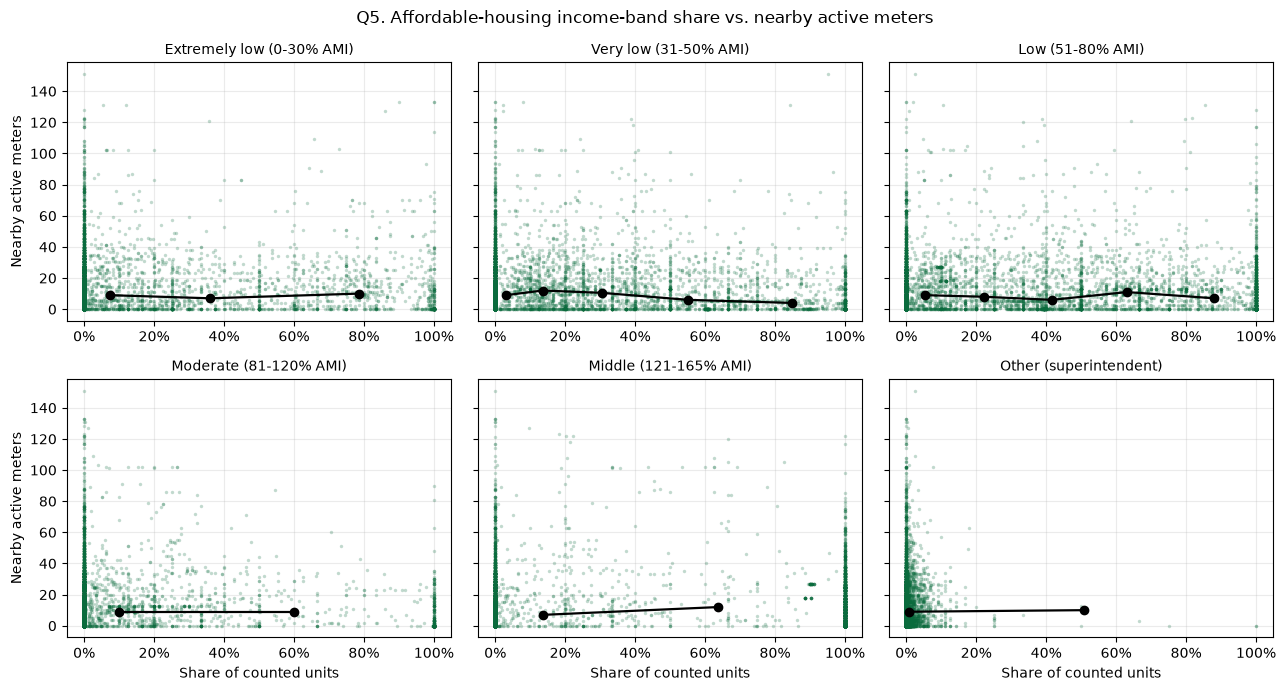

In [36]:
band_titles = {
    'share_eli': 'Extremely low (0-30% AMI)',
    'share_vli': 'Very low (31-50% AMI)',
    'share_low': 'Low (51-80% AMI)',
    'share_moderate': 'Moderate (81-120% AMI)',
    'share_middle': 'Middle (121-165% AMI)',
    'share_other_income': 'Other (superintendent)',
}

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, band in zip(axes.ravel(), income_share_cols):
    part = buildings.dropna(subset=[band, 'meters_nearby'])
    ax.scatter(part[band], part['meters_nearby'], s=6, alpha=.25, color='#0a6b3d', linewidths=0)
    deciles = pd.qcut(part[band], 10, duplicates='drop')
    medians = part.groupby(deciles, observed=True)['meters_nearby'].median()
    ax.plot([interval.mid for interval in medians.index], medians.values,
            color='black', marker='o', linewidth=1.6)
    ax.set_title(band_titles[band], fontsize=10)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.grid(alpha=.25)
    ax.set_axisbelow(True)
for ax in axes[:, 0]:
    ax.set_ylabel('Nearby active meters')
for ax in axes[1, :]:
    ax.set_xlabel('Share of counted units')
fig.suptitle('Q5. Affordable-housing income-band share vs. nearby active meters')
plt.tight_layout()
plt.show()


## Q6. New affordable units and nearby active meters by community board

Abdelrahman Mohamed. One point per community board that has at least one new-construction record. The board code is printed for the extreme points only, because 59 labels would overlap.


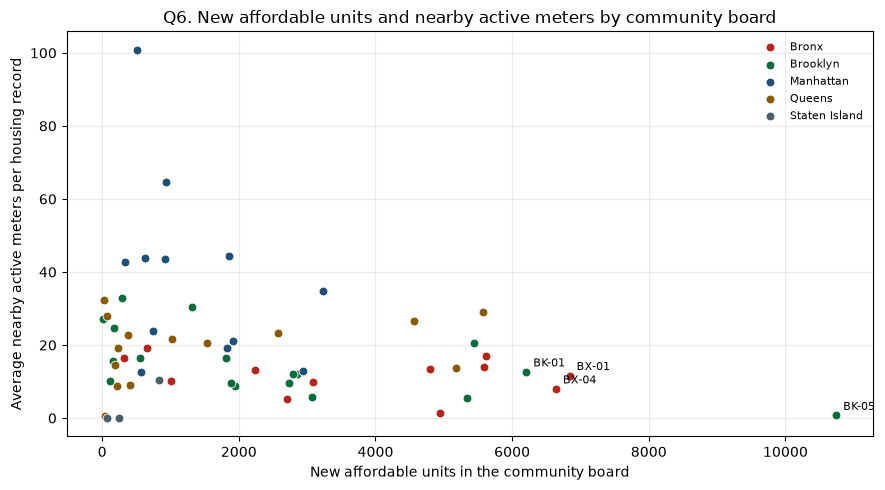

In [37]:
q6 = cb_summary.dropna(subset=['new_affordable_units', 'avg_meters_nearby'])

fig, ax = plt.subplots(figsize=(9, 5))
for borough, colour in BOROUGH_COLORS.items():
    part = q6[q6['borough'] == borough]
    ax.scatter(part['new_affordable_units'], part['avg_meters_nearby'], s=40,
               color=colour, label=borough.title(), edgecolors='white', linewidths=.6)
for _, row in q6.nlargest(4, 'new_affordable_units').iterrows():
    ax.annotate(row['cb_id'], (row['new_affordable_units'], row['avg_meters_nearby']),
                textcoords='offset points', xytext=(5, 4), fontsize=8)
ax.set_xlabel('New affordable units in the community board')
ax.set_ylabel('Average nearby active meters per housing record')
ax.set_title('Q6. New affordable units and nearby active meters by community board')
ax.legend(fontsize=8, frameon=False)
ax.grid(alpha=.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## Q7. Geographic distribution of affordable housing and active parking meters

Mohamed Wael. The only chart that puts both datasets on the same canvas. It is a validation view as much as an answer: if the coordinates were wrong, the two layers would not align with the city's shape.


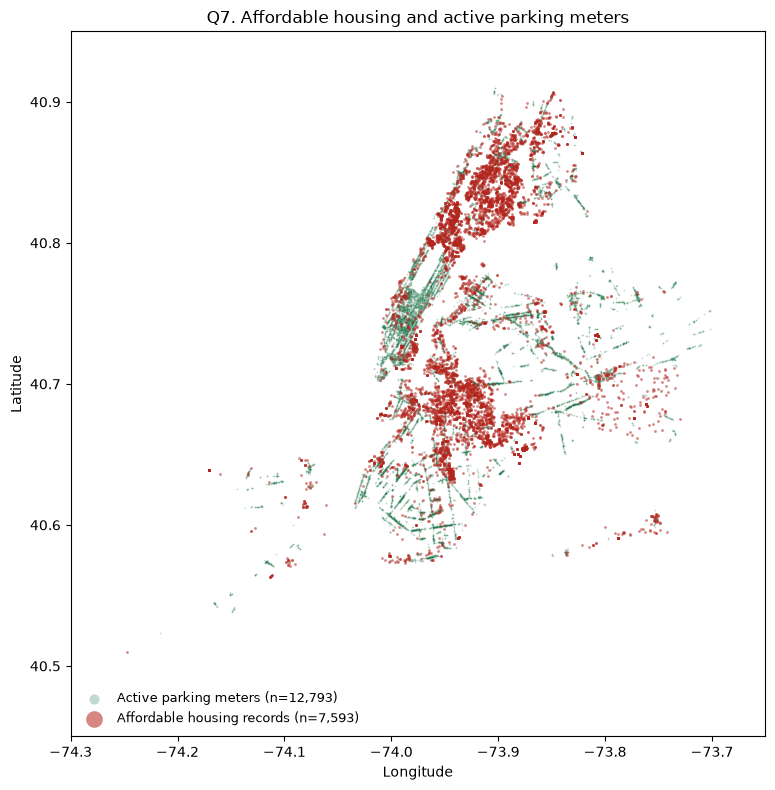

In [38]:
housing_map = buildings.dropna(subset=['lat', 'lon'])
meter_map = active.dropna(subset=['lat', 'lon'])

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(meter_map['lon'], meter_map['lat'], s=1.5, alpha=.25, color='#0a6b3d',
           linewidths=0, label=f'Active parking meters (n={len(meter_map):,})')
ax.scatter(housing_map['lon'], housing_map['lat'], s=4, alpha=.55, color='#b3261e',
           linewidths=0, label=f'Affordable housing records (n={len(housing_map):,})')
ax.set_xlim(-74.30, -73.65)
ax.set_ylim(40.45, 40.95)
ax.set_aspect(1 / np.cos(np.radians(40.72)))
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Q7. Affordable housing and active parking meters')
ax.legend(markerscale=6, fontsize=9, loc='lower left', frameon=False)
plt.tight_layout()
plt.show()


## Q8. Meter status by proximity to new affordable housing

Mohamed Wael. Shares are computed within each group, and the counts are printed so the small UNKNOWN group is not read as a finding.


status                 ACTIVE  INACTIVE  UNKNOWN
new_housing_proximity                           
New housing nearby       8584      1938       34
No new housing nearby    4209       825        2

status                 ACTIVE  INACTIVE  UNKNOWN
new_housing_proximity                           
New housing nearby       81.3      18.4      0.3
No new housing nearby    83.6      16.4      0.0


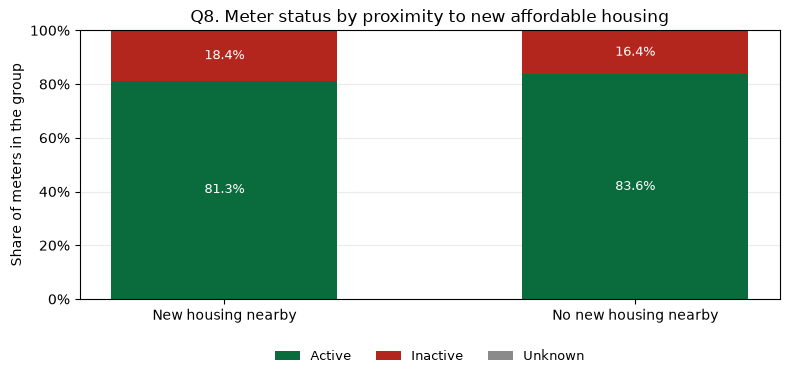

In [39]:
q8 = meters.dropna(subset=['near_new_housing', 'status']).copy()
q8['new_housing_proximity'] = q8['near_new_housing'].map(
    {0.0: 'No new housing nearby', 1.0: 'New housing nearby'})

q8_counts = pd.crosstab(q8['new_housing_proximity'], q8['status'])
q8_shares = pd.crosstab(q8['new_housing_proximity'], q8['status'], normalize='index')
print(q8_counts.to_string())
print()
print((q8_shares * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
bottom = np.zeros(len(q8_shares))
status_colours = {'ACTIVE': '#0a6b3d', 'INACTIVE': '#b3261e', 'UNKNOWN': '#8a8a8a'}
for status in ['ACTIVE', 'INACTIVE', 'UNKNOWN']:
    values = q8_shares[status].values
    ax.bar(q8_shares.index, values, bottom=bottom, color=status_colours[status],
           label=status.title(), width=.55)
    for position, (value, base) in enumerate(zip(values, bottom)):
        if value > .03:
            ax.text(position, base + value / 2, f'{value:.1%}', ha='center',
                    va='center', color='white', fontsize=9)
    bottom += values
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylabel('Share of meters in the group')
ax.set_title('Q8. Meter status by proximity to new affordable housing')
ax.legend(fontsize=9, frameon=False, ncol=3, loc='lower center', bbox_to_anchor=(.5, -.28))
ax.grid(axis='y', alpha=.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## Q9. Total housing units vs. nearby active meters

Kareem Alguineedy. The x axis is logarithmic because building size has a long right tail from 1 to 1,320 units.


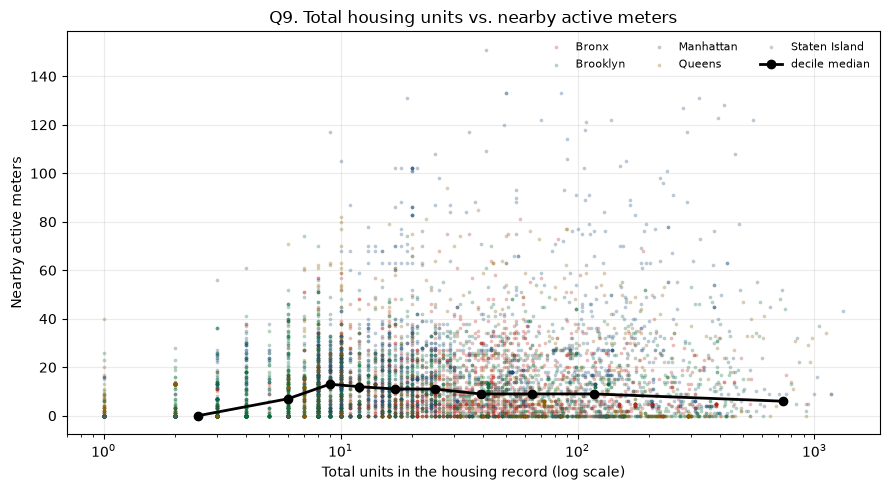

In [40]:
q9 = buildings.dropna(subset=['total_units', 'meters_nearby'])

fig, ax = plt.subplots(figsize=(9, 5))
for borough, colour in BOROUGH_COLORS.items():
    part = q9[q9['borough'] == borough]
    ax.scatter(part['total_units'], part['meters_nearby'], s=7, alpha=.3,
               color=colour, linewidths=0, label=borough.title())
size_bins = pd.qcut(q9['total_units'], 10, duplicates='drop')
size_medians = q9.groupby(size_bins, observed=True)['meters_nearby'].median()
ax.plot([interval.mid for interval in size_medians.index], size_medians.values,
        color='black', marker='o', linewidth=2, label='decile median')
ax.set_xscale('log')
ax.set_xlabel('Total units in the housing record (log scale)')
ax.set_ylabel('Nearby active meters')
ax.set_title('Q9. Total housing units vs. nearby active meters')
ax.legend(fontsize=8, ncol=3, frameon=False)
ax.grid(alpha=.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## Q10. Meter time-limit categories by proximity to affordable housing

Kareem Alguineedy. The limit is the first "HR" rule in the meter-hours text, so a meter with several daily rules is represented by its daytime rule only.


time_limit_group              1 hr  2 hr  3 hr  4-6 hr  7+ hr (all day)
housing_proximity                                                      
Affordable housing nearby      345  9253  2017     199              124
No affordable housing nearby    58  2940   397     103               50

time_limit_group              1 hr  2 hr  3 hr  4-6 hr  7+ hr (all day)
housing_proximity                                                      
Affordable housing nearby      2.9  77.5  16.9     1.7              1.0
No affordable housing nearby   1.6  82.9  11.2     2.9              1.4


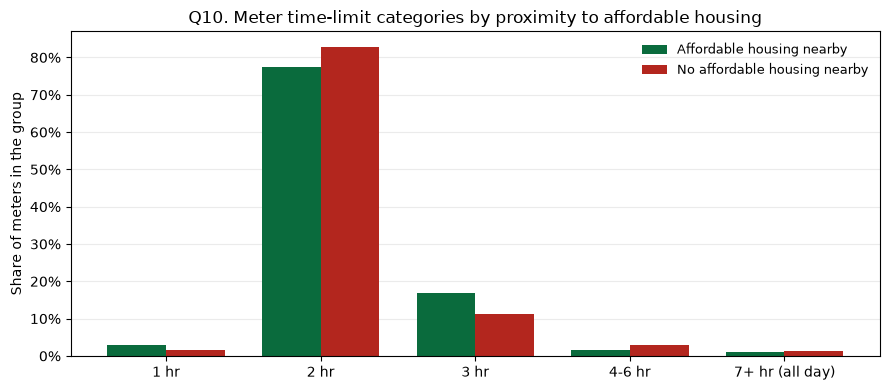

In [41]:
q10 = meters.dropna(subset=['time_limit_group', 'near_housing']).copy()
q10['housing_proximity'] = q10['near_housing'].map(
    {0.0: 'No affordable housing nearby', 1.0: 'Affordable housing nearby'})

q10_counts = pd.crosstab(q10['housing_proximity'], q10['time_limit_group'])
q10_shares = pd.crosstab(q10['housing_proximity'], q10['time_limit_group'], normalize='index')
print(q10_counts.to_string())
print()
print((q10_shares * 100).round(1).to_string())

groups = list(q10_shares.index)
limits = list(q10_shares.columns)
positions = np.arange(len(limits))
width = .38

fig, ax = plt.subplots(figsize=(9, 4))
for offset, (group, colour) in zip([-width / 2, width / 2],
                                   zip(groups, ['#0a6b3d', '#b3261e'])):
    ax.bar(positions + offset, q10_shares.loc[group].values, width=width,
           color=colour, label=group)
ax.set_xticks(positions, limits)
ax.set_ylabel('Share of meters in the group')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title('Q10. Meter time-limit categories by proximity to affordable housing')
ax.legend(fontsize=9, frameon=False)
ax.grid(axis='y', alpha=.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## Q11. Affordable-unit share vs. nearby active meters

Deema Seada. `affordable_share` is counted affordable units divided by total units in the building.


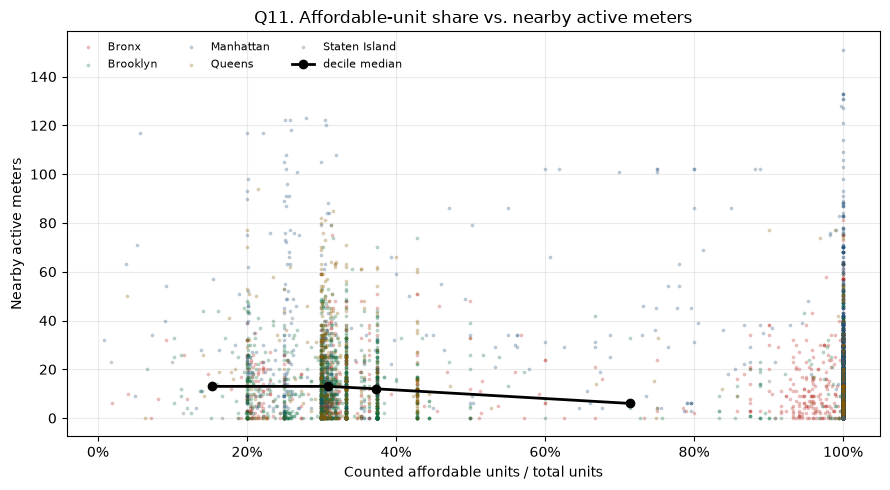

In [42]:
q11 = buildings.dropna(subset=['affordable_share', 'meters_nearby'])

fig, ax = plt.subplots(figsize=(9, 5))
for borough, colour in BOROUGH_COLORS.items():
    part = q11[q11['borough'] == borough]
    ax.scatter(part['affordable_share'], part['meters_nearby'], s=7, alpha=.3,
               color=colour, linewidths=0, label=borough.title())
share_bins = pd.qcut(q11['affordable_share'], 10, duplicates='drop')
share_medians = q11.groupby(share_bins, observed=True)['meters_nearby'].median()
ax.plot([interval.mid for interval in share_medians.index], share_medians.values,
        color='black', marker='o', linewidth=2, label='decile median')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel('Counted affordable units / total units')
ax.set_ylabel('Nearby active meters')
ax.set_title('Q11. Affordable-unit share vs. nearby active meters')
ax.legend(fontsize=8, ncol=3, frameon=False)
ax.grid(alpha=.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## Q12. Project duration with and without a nearby active meter

Deema Seada. Duration is measured from the project start date, which the data dictionary defines as the loan closing or regulatory agreement, to the building completion date. A quarter of these records have a duration of zero days, so the box is read together with the median.


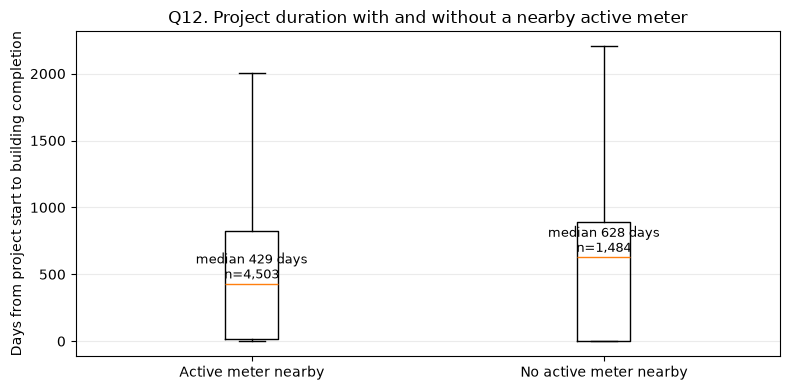

In [43]:
q12_plot = buildings.dropna(subset=['duration_days', 'near_meter']).copy()
q12_plot['meter_proximity'] = q12_plot['near_meter'].map(
    {0.0: 'No active meter nearby', 1.0: 'Active meter nearby'})

near_duration = q12_plot.loc[q12_plot['near_meter'] == 1, 'duration_days']
far_duration = q12_plot.loc[q12_plot['near_meter'] == 0, 'duration_days']

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([near_duration, far_duration],
           tick_labels=['Active meter nearby', 'No active meter nearby'],
           showfliers=False)
for position, series in enumerate([near_duration, far_duration], start=1):
    ax.text(position, series.median() + 40, f'median {series.median():.0f} days\nn={len(series):,}',
            ha='center', fontsize=9)
ax.set_ylabel('Days from project start to building completion')
ax.set_title('Q12. Project duration with and without a nearby active meter')
ax.grid(axis='y', alpha=.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


# Step 14: Findings, limits and impact

## Main question

We investigated how the locations of affordable-housing records relate geographically to the current locations and status of NYC parking meters. This matters because housing and curbside infrastructure are planned by different city systems, but residents experience them in the same neighbourhoods.

## Answers to the twelve questions

- **Q1. Meters per 1,000 affordable units.** The ratio runs from **13.2 in the Bronx** and 40.4 in Brooklyn, through 44.8 on Staten Island and 53.3 in Manhattan, to **80.8 in Queens** — a sixfold spread. Staten Island is the exception to the pattern: it has the fewest meters near housing (2.2 on average) but a mid-range ratio, because it also has the fewest affordable units. The ratio describes supply per unit, not access.
- **Q2. Share near a meter by completion year.** It ranges from **53.6% for 2016 completions to 87.6% for 2015**, with no monotonic trend; the 2020–2026 cohort sits between 78% and 85%. Because the meters are a current snapshot, this series cannot show whether meters existed when each building opened.
- **Q3. New construction vs. preservation.** New-construction records have a **median of 9 nearby active meters against 7 for preservation** (Mann-Whitney p = 2.6 × 10⁻⁶). The gap is real but small next to the spread inside each group.
- **Q4. Three-bedroom-plus share.** A weak negative rank correlation, **rho = −0.18** (n = 7,564): records with a larger share of family-sized units tend to sit where there are slightly fewer meters nearby.
- **Q5. Income-band composition.** The only band with a non-trivial correlation is **middle income (121–165% AMI), rho = +0.16**; very-low and low income are weakly negative (−0.05 and −0.04) and extremely-low income is indistinguishable from zero (+0.01, p = 0.43). Buildings with more middle-income units are slightly more likely to be in denser, better-metered areas.
- **Q6. Community boards.** The correlation between new affordable units and average nearby meters is **rho = −0.22 with n = 59 and p = 0.10**, which is not distinguishable from no relationship at this sample size. The chart is a screening view, not evidence.
- **Q7. Geographic overlap.** 7,593 housing records and 12,793 active meters plot onto the same street grid. Overlap is dense in Manhattan, western Brooklyn and Queens and sparse on Staten Island and in the eastern Rockaways.
- **Q8. Meter status.** Inactive meters are **18.4% of meters near new affordable housing against 16.4% elsewhere**; the difference is 2 percentage points (chi-square on the ACTIVE and INACTIVE rows, p = 0.002). The UNKNOWN group is 34 meters near new housing and 2 elsewhere, too small to interpret and left out of the test.
- **Q9. Building size.** **rho = +0.17** (n = 7,593): larger records have slightly more meters nearby, which is what a density effect would look like.
- **Q10. Time limits.** Three-hour meters are **16.9% of meters near affordable housing against 11.2% elsewhere**, while two-hour meters are 77.5% against 82.9%. Longer limits (4–6 hours and all-day) are slightly more common away from housing (chi-square p = 1.6 × 10⁻²²).
- **Q11. Affordable share.** **rho = −0.20** (n = 7,564): buildings with a higher affordable share tend to have fewer meters nearby.
- **Q12. Project duration.** Records with an active meter nearby have a **median of 429 days against 628 days without one** (Mann-Whitney p = 0.0011). This is a comparison of two groups of records, not a measured effect of parking on delivery time.

The correlations in Q4, Q5, Q9 and Q11 are all below 0.25 in absolute value. They are statistically visible because the sample is large, but they describe weak tendencies in a noisy relationship, not a rule.

## What surprised us

The borough ratio and the proximity measure disagree. Staten Island has by far the fewest meters near affordable housing but a higher ratio per unit than Brooklyn, and Queens leads the ratio while sitting mid-table on average nearby meters. That gap is the clearest illustration of why the unit of analysis has to be stated with the number.

## Limitations

- The housing file contains project/building records; a row is not necessarily a unique physical building. 123 buildings appear in 247 project records, so summing `all_counted_units` over records counts some units more than once; counting every repeated building once instead removes 1,154 units, 0.36% of the citywide total.
- Parking-meter locations and status are a current snapshot, not historical observations matched to each project's completion date.
- A meter is not the same as a parking space, and this analysis does not measure total parking supply, occupancy, price, or parking demand.
- The grid is a square-window approximation rather than a circular distance or walking/road-network distance. Its corners extend farther than its sides, and the result depends on the window: 63.9% of buildings are near a meter at a 2-cell reach, 75.7% at 3 cells and 87.8% at 5 cells.
- 1,958 of 9,551 housing records (20.5%) have no usable coordinates after cleaning, so they cannot receive a proximity measure. This is not assumed to mean all such records are confidential: 1,949 are marked CONFIDENTIAL and 9 are not.
- `duration_days` runs from the loan closing or regulatory agreement to building completion, not from construction start. A quarter of the records used in Q12 have a duration of zero days, and 20 records with a completion date before the start date are set to missing rather than repaired.
- The income-band blank-as-zero assumption is supported by the validation cell: the six bands sum exactly to `all_counted_units` for 100% of the 9,522 records where that total exists.
- The proximity measures count nearby records; dense areas may have many meters or housing records close together. Results show association, not causation.

## Potential impact

City planners and housing advocates could use these results as an initial screening view to identify boroughs and community boards for closer investigation. Transportation and curb-management teams could combine this analysis with parking occupancy, curb regulations, transit access, and historical meter records before making policy decisions. The notebook alone does not justify adding or removing meters or changing housing policy.

## Final interpretation

The strongest supported conclusion is that affordable-housing records and active parking meters frequently occur within the selected geographic window — 75.7% of records with coordinates have at least one active meter in the 7 × 7 cell window — but the measured level of overlap changes substantially with the window size, and the associations between housing composition and meter counts are weak. The analysis is useful for exploratory screening, not for causal claims or operational decisions without additional data.
